In [191]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [192]:
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Visualization settings
sns.set_theme(style='whitegrid')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 120

print("All libraries imported successfully!")

All libraries imported successfully!


In [193]:
import os

# Create folder
os.makedirs("visualizations", exist_ok=True)

# Save visualization
plt.savefig(
    "visualizations/missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1440x720 with 0 Axes>

Data Import Customer

In [194]:
df = pd.read_excel ("C:/Users/HP/Downloads/customer_churn_data_raw.xlsx")
print (df)                

    customerid        name country          state  gender        dob interests  pincode
0   0002-ORFBO      keshav   India    Maharashtra    Male 1982-04-12    travel      NaN
1   0003-MKNFE      raghav   India      Karnataka    Male 1995-11-23       NaN      NaN
2   0004-TLHLJ      lalita   India          Delhi  Female 1978-02-15     movie      NaN
3   0011-IGKFF       mohan   India       Nagaland    Male 2001-08-30       NaN      NaN
4   0013-EXCHZ        mira   India          Delhi  Female 1990-05-05     drama      NaN
5   0013-MHZWF       durga     NaN          Delhi   Women 1988-12-10       NaN      NaN
6   0013-SMEOE        mina   India      Meghalaya  Female 1976-09-21       NaN      NaN
7   0014-BMAQU       madan   India      Rajasthan    Male 1999-03-14       NaN      NaN
8   0015-UOCOJ        maya     NaN      Kathmandu   Women 1985-07-07       NaN      NaN
9   0016-QLJIS       arjun   Nepal      Kathmandu    Male 1993-10-29       NaN      NaN
10  0017-DINOC       shiva   Ind

In [195]:
print(df.head())

   customerid    name country        state  gender        dob interests  pincode
0  0002-ORFBO  keshav   India  Maharashtra    Male 1982-04-12    travel      NaN
1  0003-MKNFE  raghav   India    Karnataka    Male 1995-11-23       NaN      NaN
2  0004-TLHLJ  lalita   India        Delhi  Female 1978-02-15     movie      NaN
3  0011-IGKFF   mohan   India     Nagaland    Male 2001-08-30       NaN      NaN
4  0013-EXCHZ    mira   India        Delhi  Female 1990-05-05     drama      NaN


In [196]:
print(df.tail())

    customerid        name country          state  gender        dob interests  pincode
16  0020-JDNXP       rikim   India      Meghalaya  Female 1994-08-19       NaN      NaN
17  0021-IKXGC    vishakha   India      Rajasthan  Female 2000-09-02       NaN      NaN
18  0022-TCJCI  raghvendra   India      Telangana    Male 1983-12-30       NaN      NaN
19  0023-HGHWL     rishabh   India  Uttar Pradesh     Men 1991-05-14       NaN      NaN
20  0023-UYUPN      sudevi   India    Maharashtra   Women 1977-10-06       NaN      NaN


Data Understanding

In [197]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 21
Total Columns: 8


In [198]:
print(df.columns.tolist())

['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']


In [199]:
print(df.dtypes)

customerid            object
name                  object
country               object
state                 object
gender                object
dob           datetime64[ns]
interests             object
pincode              float64
dtype: object


In [200]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   customerid  21 non-null     object        
 1   name        21 non-null     object        
 2   country     18 non-null     object        
 3   state       21 non-null     object        
 4   gender      21 non-null     object        
 5   dob         21 non-null     datetime64[ns]
 6   interests   4 non-null      object        
 7   pincode     0 non-null      float64       
dtypes: datetime64[ns](1), float64(1), object(6)
memory usage: 1.4+ KB


In [201]:
print(df.describe())

                                 dob  pincode
count                             21      0.0
mean   1989-08-26 12:34:17.142857088      NaN
min              1976-09-21 00:00:00      NaN
25%              1982-04-12 00:00:00      NaN
50%              1990-05-05 00:00:00      NaN
75%              1995-11-23 00:00:00      NaN
max              2004-12-01 00:00:00      NaN
std                              NaN      NaN


In [202]:
print(df.describe(include='all'))

        customerid    name country  state  gender                            dob interests  pincode
count           21      21      18     21      21                             21         4      0.0
unique          21      21       2      9       4                            NaN         4      NaN
top     0002-ORFBO  keshav   India  Delhi  Female                            NaN    travel      NaN
freq             1       1      17      4       9                            NaN         1      NaN
mean           NaN     NaN     NaN    NaN     NaN  1989-08-26 12:34:17.142857088       NaN      NaN
min            NaN     NaN     NaN    NaN     NaN            1976-09-21 00:00:00       NaN      NaN
25%            NaN     NaN     NaN    NaN     NaN            1982-04-12 00:00:00       NaN      NaN
50%            NaN     NaN     NaN    NaN     NaN            1990-05-05 00:00:00       NaN      NaN
75%            NaN     NaN     NaN    NaN     NaN            1995-11-23 00:00:00       NaN      NaN


In [203]:
for col in df.columns:
    print(
        col,
        ":", df[col].nunique()
        )

customerid : 21
name : 21
country : 2
state : 9
gender : 4
dob : 21
interests : 4
pincode : 0


In [204]:
print(df['gender'].value_counts())

gender
Female    9
Male      6
Women     3
Men       3
Name: count, dtype: int64


In [205]:
print(df['country'].value_counts())

country
India    17
Nepal     1
Name: count, dtype: int64


In [206]:
print(df['interests'].value_counts(dropna=False))

interests
NaN       17
travel     1
movie      1
drama      1
job        1
Name: count, dtype: int64


Data Quality Audit

In [207]:
print(df.isnull().sum())

customerid     0
name           0
country        3
state          0
gender         0
dob            0
interests     17
pincode       21
dtype: int64


In [208]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage.round(2))

customerid      0.00
name            0.00
country        14.29
state           0.00
gender          0.00
dob             0.00
interests      80.95
pincode       100.00
dtype: float64


In [209]:
missing_report = pd.DataFrame({
    'Column': df.columns,
    'Missing_Values': df.isnull().sum().values,
    'Missing_Percentage': missing_percentage.values
})

print(missing_report)

       Column  Missing_Values  Missing_Percentage
0  customerid               0            0.000000
1        name               0            0.000000
2     country               3           14.285714
3       state               0            0.000000
4      gender               0            0.000000
5         dob               0            0.000000
6   interests              17           80.952381
7     pincode              21          100.000000


In [210]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [211]:
print(
    "Duplicate Customer IDs:",
    df['customerid'].duplicated().sum()
)

Duplicate Customer IDs: 0


In [212]:
print(df['gender'].unique())

['Male' 'Female' 'Women' 'Men']


In [213]:
empty_columns = df.columns[
    df.isnull().all()
]

print("Completely Empty Columns:", list(empty_columns))

Completely Empty Columns: ['pincode']


Visualization

1. Missing Values Analysis

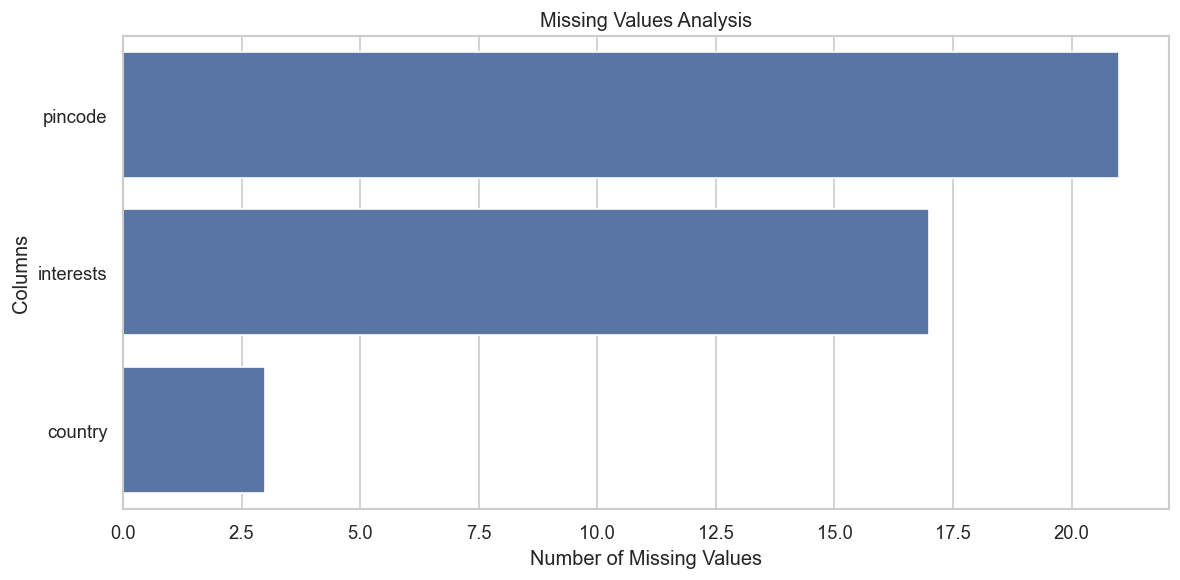

In [214]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=missing.values, y=missing.index)
plt.title("Missing Values Analysis")
plt.xlabel("Number of Missing Values")
plt.ylabel("Columns")
plt.tight_layout()
plt.savefig("visualizations/01_missing_values.png", dpi=300)
plt.show()

2. Gender Distribution

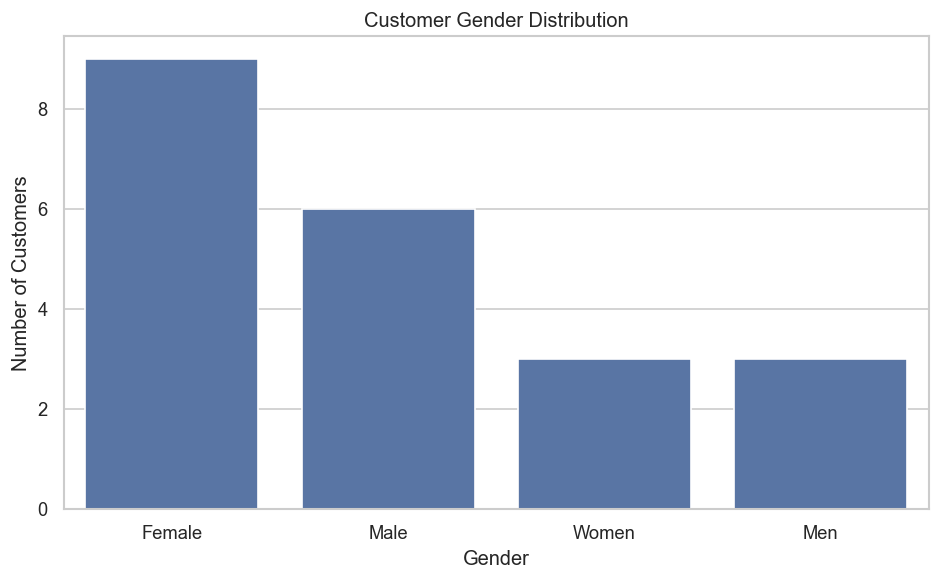

In [215]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="gender", order=df["gender"].value_counts().index)
plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/02_gender_distribution.png", dpi=300)
plt.show()

3. Country-wise Customer Distribution

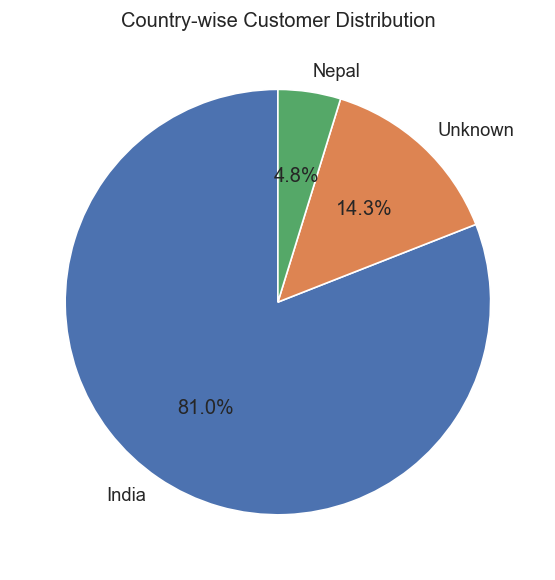

In [216]:
country_data = df["country"].fillna("Unknown").value_counts()

plt.figure(figsize=(8, 5))
plt.pie(
    country_data.values,
    labels=country_data.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Country-wise Customer Distribution")
plt.tight_layout()
plt.savefig("visualizations/03_country_distribution.png", dpi=300)
plt.show()

4. Customer Age Distribution

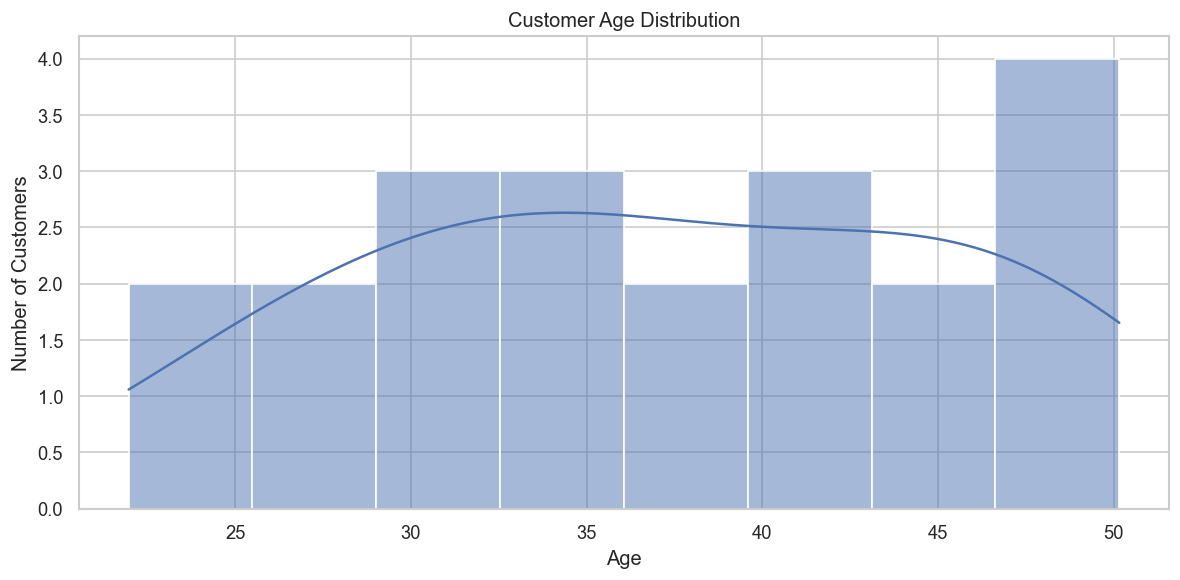

In [217]:

df["dob"] = pd.to_datetime(df["dob"], errors="coerce")

today = pd.Timestamp.today()
df["age"] = ((today - df["dob"]).dt.days / 365.25)

plt.figure(figsize=(10, 5))
sns.histplot(df["age"].dropna(), bins=8, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/04_age_distribution.png", dpi=300)
plt.show()

Import Data Subscription

In [218]:
df2 = pd.read_excel ("C:/Users/HP/Downloads/customer_churn_data_raw.xlsx", sheet_name="db_subscription")
print (df2) 

    customerid subscription_start_date subscription_type renewal_date plan_type contract_type cancellation_date  \
0   0002-ORFBO              2021-03-15          Refferal   2025-03-15  Standard        Annual               NaN   
1   0003-MKNFE              2020-08-01              Paid   2024-08-01   Premium        Annual        2024-09-10   
2   0004-TLHLJ              2022-11-20           Organic   2025-11-20     Basic       Monthly               NaN   
3   0011-IGKFF              2019-05-10              Paid   2025-05-10   Premium        Annual               NaN   
4   0013-EXCHZ              2023-01-05          Refferal   2024-01-05  Standard       Monthly        2024-02-28   
5   0013-MHZWF              2022-06-18              Paid   2025-06-18  Standard        Annual               NaN   
6   0013-SMEOE              2021-09-30          Refferal   2024-09-30     Basic       Monthly        2024-11-15   
7   0014-BMAQU              2020-02-14           Organic   2025-02-14   Premium 

In [219]:
print("Dataset Shape:")
print(df2.shape)

print("\nFirst 5 Records:")
display(df2.head())

print("\nLast 5 Records:")
display(df2.tail())

print("\nColumn Names:")
print(df2.columns.tolist())

print("\nData Types:")
print(df2.dtypes)

print("\nDataset Information:")
df2.info()

print("\nStatistical Summary:")
display(df2.describe())

Dataset Shape:
(21, 11)

First 5 Records:


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88



Last 5 Records:


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
16,0020-JDNXP,2022-01-19,Organic,2024-01-19,Premium,Annual,NaN,NaN,20.99,550,62
17,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,NaN,NaN,13.99,840,27
18,0022-TCJCI,2023-09-14,Refferal,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99
19,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,NaN,NaN,22.99,1955,7
20,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,NaN,NaN,13.99,790,47



Column Names:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Data Types:
customerid                  object
subscription_start_date     object
subscription_type           object
renewal_date                object
plan_type                   object
contract_type               object
cancellation_date           object
cancellation_reason         object
monthly_charges            float64
cltv                         int64
churn_score                  int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-

,monthly_charges,cltv,churn_score
count,21.000000,21.000000,21.000000
mean,18.847143,823.523810,43.285714
std,17.754677,668.913195,32.292635
min,6.990000,42.000000,3.000000
25%,12.990000,240.000000,14.000000
50%,13.990000,640.000000,34.000000
75%,20.990000,1150.000000,76.000000
max,92.990000,2185.000000,99.000000


In [220]:
print("Missing Values:")
display(df2.isnull().sum())

print("\nMissing Values Percentage:")
display((df2.isnull().mean() * 100).round(2))

print("\nDuplicate Records:")
print(df2.duplicated().sum())

print("\nDuplicate Customer IDs:")
print(df2["customerid"].duplicated().sum())

print("\nSubscription Type Counts:")
print(df2["subscription_type"].value_counts())

print("\nPlan Type Counts:")
print(df2["plan_type"].value_counts())

print("\nContract Type Counts:")
print(df2["contract_type"].value_counts())

Missing Values:


customerid                  0
subscription_start_date     0
subscription_type           0
renewal_date                0
plan_type                   0
contract_type               0
cancellation_date          15
cancellation_reason        15
monthly_charges             0
cltv                        0
churn_score                 0
dtype: int64


Missing Values Percentage:


customerid                  0.00
subscription_start_date     0.00
subscription_type           0.00
renewal_date                0.00
plan_type                   0.00
contract_type               0.00
cancellation_date          71.43
cancellation_reason        71.43
monthly_charges             0.00
cltv                        0.00
churn_score                 0.00
dtype: float64


Duplicate Records:
0

Duplicate Customer IDs:
0

Subscription Type Counts:
subscription_type
Organic     9
Refferal    6
Paid        6
Name: count, dtype: int64

Plan Type Counts:
plan_type
Standard    9
Premium     7
Basic       5
Name: count, dtype: int64

Contract Type Counts:
contract_type
Annual     12
Monthly     9
Name: count, dtype: int64


In [221]:
# Create a copy of original dataset

df_clean = df2.copy()

print("Original dataset:", df2.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (21, 11)
Working dataset: (21, 11)


In [222]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df_clean.columns.tolist())

['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']


In [223]:
# Check duplicate records

print("Total duplicate rows:", df_clean.duplicated().sum())

# Check duplicate customer IDs

print("Duplicate Customer IDs:",
      df_clean["customerid"].duplicated().sum())

Total duplicate rows: 0
Duplicate Customer IDs: 0


In [224]:
# Remove extra spaces

text_columns = df_clean.select_dtypes(include="object").columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Correct subscription type spelling

df_clean["subscription_type"] = (
    df_clean["subscription_type"]
    .replace({"Refferal": "Referral"})
)

print(df_clean["subscription_type"].value_counts())

subscription_type
Organic     9
Referral    6
Paid        6
Name: count, dtype: int64


In [225]:
date_columns = [
    "subscription_start_date",
    "renewal_date",
    "cancellation_date"
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        errors="coerce"
    )

print(df_clean[date_columns].dtypes)

subscription_start_date    datetime64[ns]
renewal_date               datetime64[ns]
cancellation_date          datetime64[ns]
dtype: object


In [226]:
numeric_columns = [
    "monthly_charges",
    "cltv",
    "churn_score"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

display(df_clean[numeric_columns].describe())

,monthly_charges,cltv,churn_score
count,21.000000,21.000000,21.000000
mean,18.847143,823.523810,43.285714
std,17.754677,668.913195,32.292635
min,6.990000,42.000000,3.000000
25%,12.990000,240.000000,14.000000
50%,13.990000,640.000000,34.000000
75%,20.990000,1150.000000,76.000000
max,92.990000,2185.000000,99.000000


In [227]:
print("Cleaned Dataset Shape:")
print(df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nData Types:")
print(df_clean.dtypes)

display(df_clean.head())

Cleaned Dataset Shape:
(21, 11)

Missing Values:
customerid                  0
subscription_start_date     0
subscription_type           0
renewal_date                0
plan_type                   0
contract_type               0
cancellation_date          15
cancellation_reason        15
monthly_charges             0
cltv                        0
churn_score                 0
dtype: int64

Data Types:
customerid                         object
subscription_start_date    datetime64[ns]
subscription_type                  object
renewal_date               datetime64[ns]
plan_type                          object
contract_type                      object
cancellation_date          datetime64[ns]
cancellation_reason                object
monthly_charges                   float64
cltv                                int64
churn_score                         int64
dtype: object


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Referral,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Referral,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [228]:
# Create cancellation status

df_clean["cancellation_status"] = np.where(
    df_clean["cancellation_date"].notna(),
    "Cancelled",
    "No Cancellation Date"
)

print(df_clean["cancellation_status"].value_counts())

cancellation_status
No Cancellation Date    15
Cancelled                6
Name: count, dtype: int64


In [229]:
print("Subscription Type Summary:")
display(df_clean["subscription_type"].value_counts())

print("\nPlan Type Summary:")
display(df_clean["plan_type"].value_counts())

print("\nContract Type Summary:")
display(df_clean["contract_type"].value_counts())

print("\nCancellation Status Summary:")
display(df_clean["cancellation_status"].value_counts())

Subscription Type Summary:


subscription_type
Organic     9
Referral    6
Paid        6
Name: count, dtype: int64


Plan Type Summary:


plan_type
Standard    9
Premium     7
Basic       5
Name: count, dtype: int64


Contract Type Summary:


contract_type
Annual     12
Monthly     9
Name: count, dtype: int64


Cancellation Status Summary:


cancellation_status
No Cancellation Date    15
Cancelled                6
Name: count, dtype: int64

Visualization

1. Subscription Type Distribution

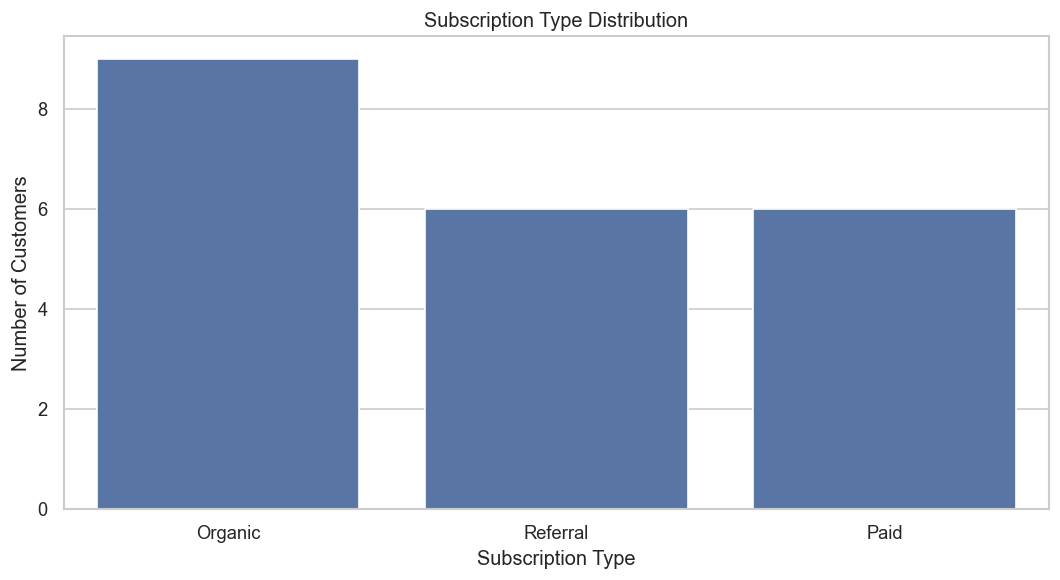

In [230]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    x="subscription_type",
    order=df_clean["subscription_type"].value_counts().index
)
plt.title("Subscription Type Distribution")
plt.xlabel("Subscription Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/01_subscription_type.png", dpi=300)
plt.show()

2. Plan Type Distribution

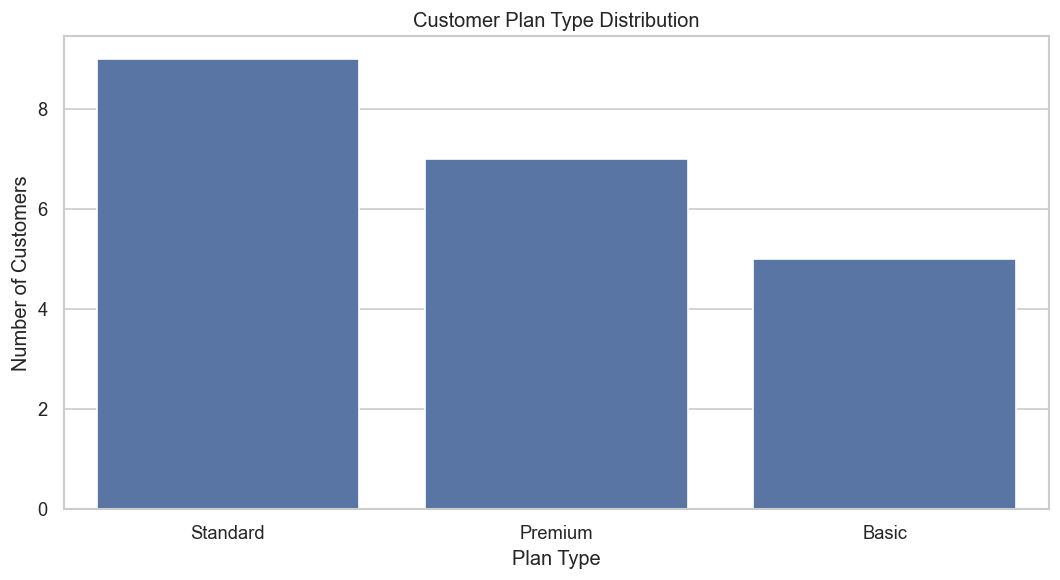

In [231]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    x="plan_type",
    order=df_clean["plan_type"].value_counts().index
)
plt.title("Customer Plan Type Distribution")
plt.xlabel("Plan Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/02_plan_type.png", dpi=300)
plt.show()

3. Contract Type Distribution

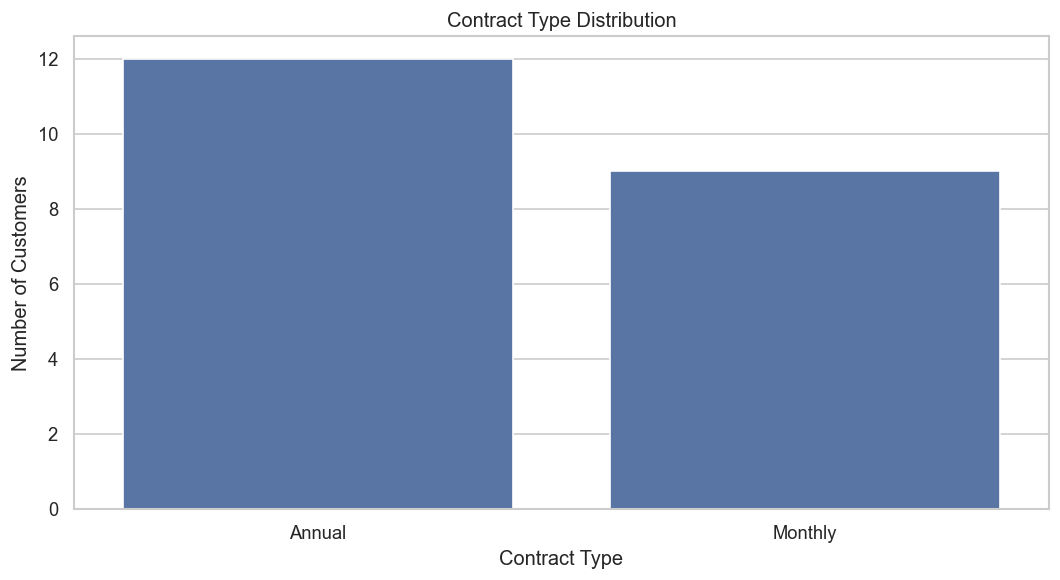

In [232]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    x="contract_type",
    order=df_clean["contract_type"].value_counts().index
)
plt.title("Contract Type Distribution")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/03_contract_type.png", dpi=300)
plt.show()

4. Cancellation Status

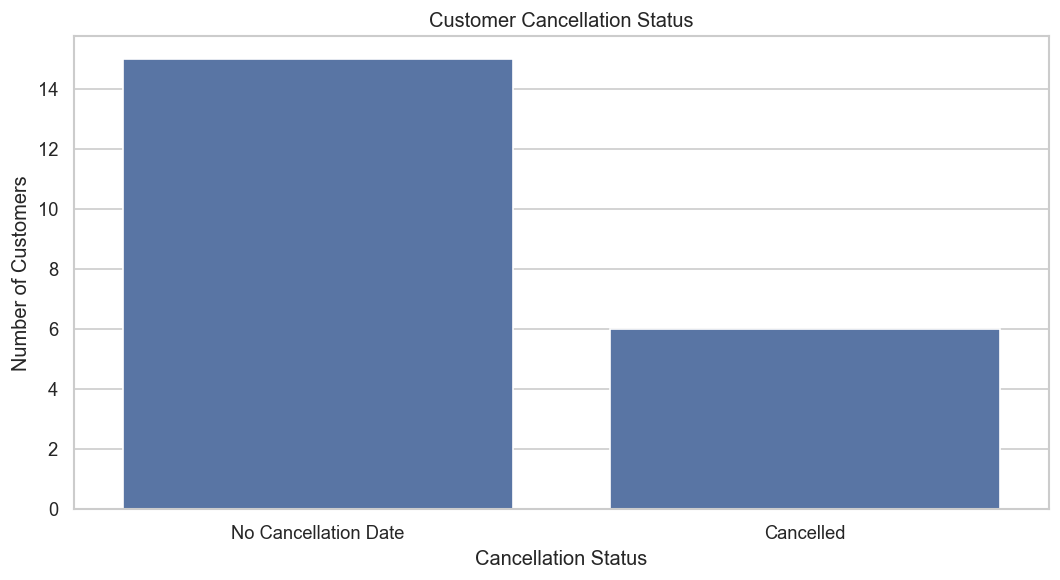

In [233]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    x="cancellation_status",
    order=df_clean["cancellation_status"].value_counts().index
)
plt.title("Customer Cancellation Status")
plt.xlabel("Cancellation Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/04_cancellation_status.png", dpi=300)
plt.show()

5. Monthly Charges Distribution

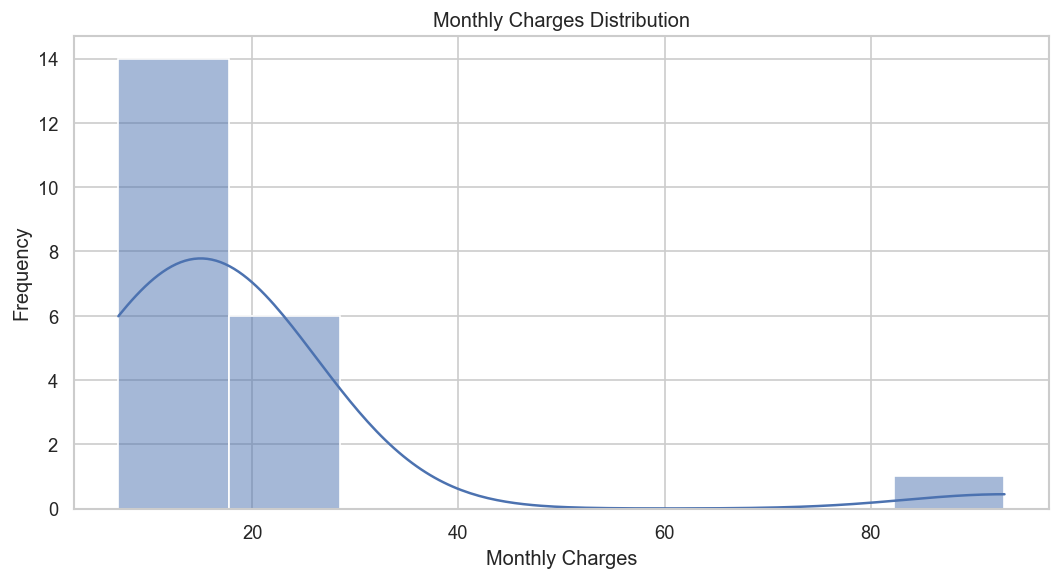

In [234]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x="monthly_charges",
    bins=8,
    kde=True
)
plt.title("Monthly Charges Distribution")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("visualizations/05_monthly_charges.png", dpi=300)
plt.show()

6. Churn Score Distribution

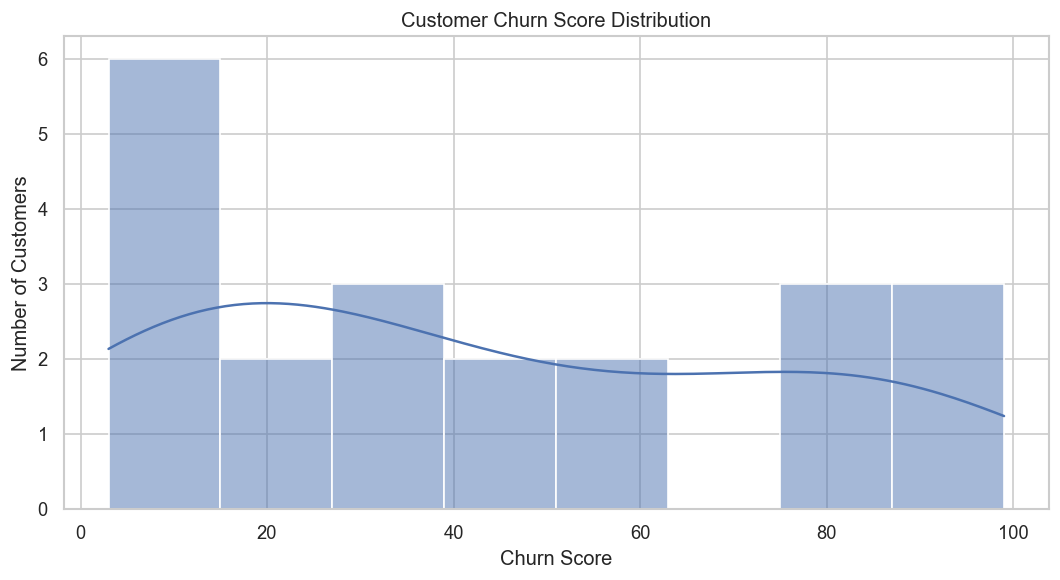

In [235]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x="churn_score",
    bins=8,
    kde=True
)
plt.title("Customer Churn Score Distribution")
plt.xlabel("Churn Score")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("visualizations/06_churn_score.png", dpi=300)
plt.show()


Import Data Customer Support 

In [239]:
df3 = pd.read_excel ("C:/Users/HP/Downloads/customer_churn_data_raw.xlsx", sheet_name="db_support")
print (df3)

   customerid complaint_date escalations  csat_score  col_1            comment
0  0003-MKNFE     2024-08-28           N          60    NaN      service issue
1  0003-MKNFE     2024-08-28           Y          10    NaN     demaned refund
2  0013-EXCHZ     2024-01-20           Y          20    NaN                NaN
3  0013-MHZWF     2025-03-18           N          90    NaN  guidance to renew
4  0013-SMEOE     2024-11-01           N          30    NaN                NaN
5  0017-IUDMW     2024-04-10           Y          25    NaN                NaN
6  0019-EFAEP     2024-09-27           Y          30    NaN                NaN
7  0022-TCJCI     2024-09-13           Y          10    NaN                NaN
8  0022-TCJCI     2024-09-14           N          90    NaN    received refund


In [240]:
print("Dataset Shape:")
print(df3.shape)

print("\nFirst 5 Records:")
display(df3.head())

print("\nLast 5 Records:")
display(df3.tail())

print("\nColumn Names:")
print(df3.columns.tolist())

print("\nData Types:")
print(df3.dtypes)

print("\nDataset Information:")
df3.info()

print("\nStatistical Summary:")
display(df3.describe(include="all"))

Dataset Shape:
(9, 6)

First 5 Records:


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28,N,60,NaN,service issue
1,0003-MKNFE,2024-08-28,Y,10,NaN,demaned refund
2,0013-EXCHZ,2024-01-20,Y,20,NaN,NaN
3,0013-MHZWF,2025-03-18,N,90,NaN,guidance to renew
4,0013-SMEOE,2024-11-01,N,30,NaN,NaN



Last 5 Records:


,customerid,complaint_date,escalations,csat_score,col_1,comment
4,0013-SMEOE,2024-11-01,N,30,NaN,NaN
5,0017-IUDMW,2024-04-10,Y,25,NaN,NaN
6,0019-EFAEP,2024-09-27,Y,30,NaN,NaN
7,0022-TCJCI,2024-09-13,Y,10,NaN,NaN
8,0022-TCJCI,2024-09-14,N,90,NaN,received refund



Column Names:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']

Data Types:
customerid                object
complaint_date    datetime64[ns]
escalations               object
csat_score                 int64
col_1                    float64
comment                   object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
 4   col_1           0 non-null      float64       
 5   comment         4 non-null      object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 564.0+ bytes

Statistical Summary:


,customerid,complaint_date,escalations,csat_score,col_1,comment
count,9,9,9,9.000000,0.0,4
unique,7,NaN,2,NaN,NaN,4
top,0003-MKNFE,NaN,Y,NaN,NaN,service issue
freq,2,NaN,5,NaN,NaN,1
mean,NaN,2024-08-24 13:20:00,NaN,40.555556,NaN,NaN
min,NaN,2024-01-20 00:00:00,NaN,10.000000,NaN,NaN
25%,NaN,2024-08-28 00:00:00,NaN,20.000000,NaN,NaN
50%,NaN,2024-09-13 00:00:00,NaN,30.000000,NaN,NaN
75%,NaN,2024-09-27 00:00:00,NaN,60.000000,NaN,NaN
max,NaN,2025-03-18 00:00:00,NaN,90.000000,NaN,NaN


In [241]:
print("Missing Values:")
print(df3.isnull().sum())

print("\nMissing Values Percentage:")
print((df3.isnull().mean() * 100).round(2))

print("\nDuplicate Records:")
print(df3.duplicated().sum())

print("\nUnique Customer IDs:")
print(df3["customerid"].nunique())

Missing Values:
customerid        0
complaint_date    0
escalations       0
csat_score        0
col_1             9
comment           5
dtype: int64

Missing Values Percentage:
customerid          0.00
complaint_date      0.00
escalations         0.00
csat_score          0.00
col_1             100.00
comment            55.56
dtype: float64

Duplicate Records:
0

Unique Customer IDs:
7


In [242]:
print("Escalation Summary:")
print(df3["escalations"].value_counts())

print("\nCSAT Score Summary:")
print(df3["csat_score"].value_counts().sort_index())

print("\nComplaint Date Range:")
print(df3["complaint_date"].min())
print(df3["complaint_date"].max())

print("\nCustomer Feedback:")
display(df3["comment"].value_counts(dropna=False))

Escalation Summary:
escalations
Y    5
N    4
Name: count, dtype: int64

CSAT Score Summary:
csat_score
10    2
20    1
25    1
30    2
60    1
90    2
Name: count, dtype: int64

Complaint Date Range:
2024-01-20 00:00:00
2025-03-18 00:00:00

Customer Feedback:


comment
NaN                  5
service issue        1
demaned refund       1
guidance to renew    1
received refund      1
Name: count, dtype: int64

In [243]:
# Create working copy

df_support_clean = df3.copy()

print("Original Dataset:", df3.shape)
print("Working Dataset:", df_support_clean.shape)

Original Dataset: (9, 6)
Working Dataset: (9, 6)


In [244]:
df_support_clean.columns = (
    df_support_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df_support_clean.columns.tolist())

['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [245]:
# Identify completely empty columns

empty_columns = [
    col for col in df_support_clean.columns
    if df_support_clean[col].isnull().all()
]

print("Empty Columns:", empty_columns)

# Remove empty columns

df_support_clean = df_support_clean.drop(
    columns=empty_columns
)

print("Updated Shape:", df_support_clean.shape)

Empty Columns: ['col_1']
Updated Shape: (9, 5)


In [246]:
df_support_clean["complaint_date"] = pd.to_datetime(
    df_support_clean["complaint_date"],
    errors="coerce"
)

print(df_support_clean["complaint_date"].dtype)

datetime64[ns]


In [247]:
df_support_clean["escalations"] = (
    df_support_clean["escalations"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print(df_support_clean["escalations"].value_counts(dropna=False))

escalations
Y    5
N    4
Name: count, dtype: Int64


In [248]:
df_support_clean["csat_score"] = pd.to_numeric(
    df_support_clean["csat_score"],
    errors="coerce"
)

print(df_support_clean["csat_score"].describe())

count     9.000000
mean     40.555556
std      31.666667
min      10.000000
25%      20.000000
50%      30.000000
75%      60.000000
max      90.000000
Name: csat_score, dtype: float64


In [249]:
df_support_clean["comment_clean"] = (
    df_support_clean["comment"]
    .astype("string")
    .str.strip()
)

df_support_clean["comment_clean"] = (
    df_support_clean["comment_clean"]
    .replace("", pd.NA)
    .fillna("No comment provided")
)

display(
    df_support_clean[
        ["customerid", "comment", "comment_clean"]
    ]
)

,customerid,comment,comment_clean
0,0003-MKNFE,service issue,service issue
1,0003-MKNFE,demaned refund,demaned refund
2,0013-EXCHZ,NaN,No comment provided
3,0013-MHZWF,guidance to renew,guidance to renew
4,0013-SMEOE,NaN,No comment provided
5,0017-IUDMW,NaN,No comment provided
6,0019-EFAEP,NaN,No comment provided
7,0022-TCJCI,NaN,No comment provided
8,0022-TCJCI,received refund,received refund


In [250]:
print("Final Dataset Shape:")
print(df_support_clean.shape)

print("\nMissing Values:")
print(df_support_clean.isnull().sum())

print("\nData Types:")
print(df_support_clean.dtypes)

print("\nDuplicate Rows:")
print(df_support_clean.duplicated().sum())

print("\nUnique Customers:")
print(df_support_clean["customerid"].nunique())

display(df_support_clean.head(10))

Final Dataset Shape:
(9, 6)

Missing Values:
customerid        0
complaint_date    0
escalations       0
csat_score        0
comment           5
comment_clean     0
dtype: int64

Data Types:
customerid                object
complaint_date    datetime64[ns]
escalations       string[python]
csat_score                 int64
comment                   object
comment_clean     string[python]
dtype: object

Duplicate Rows:
0

Unique Customers:
7


,customerid,complaint_date,escalations,csat_score,comment,comment_clean
0,0003-MKNFE,2024-08-28,N,60,service issue,service issue
1,0003-MKNFE,2024-08-28,Y,10,demaned refund,demaned refund
2,0013-EXCHZ,2024-01-20,Y,20,NaN,No comment provided
3,0013-MHZWF,2025-03-18,N,90,guidance to renew,guidance to renew
4,0013-SMEOE,2024-11-01,N,30,NaN,No comment provided
5,0017-IUDMW,2024-04-10,Y,25,NaN,No comment provided
6,0019-EFAEP,2024-09-27,Y,30,NaN,No comment provided
7,0022-TCJCI,2024-09-13,Y,10,NaN,No comment provided
8,0022-TCJCI,2024-09-14,N,90,received refund,received refund


Visualization

1. CSAT Score Distribution

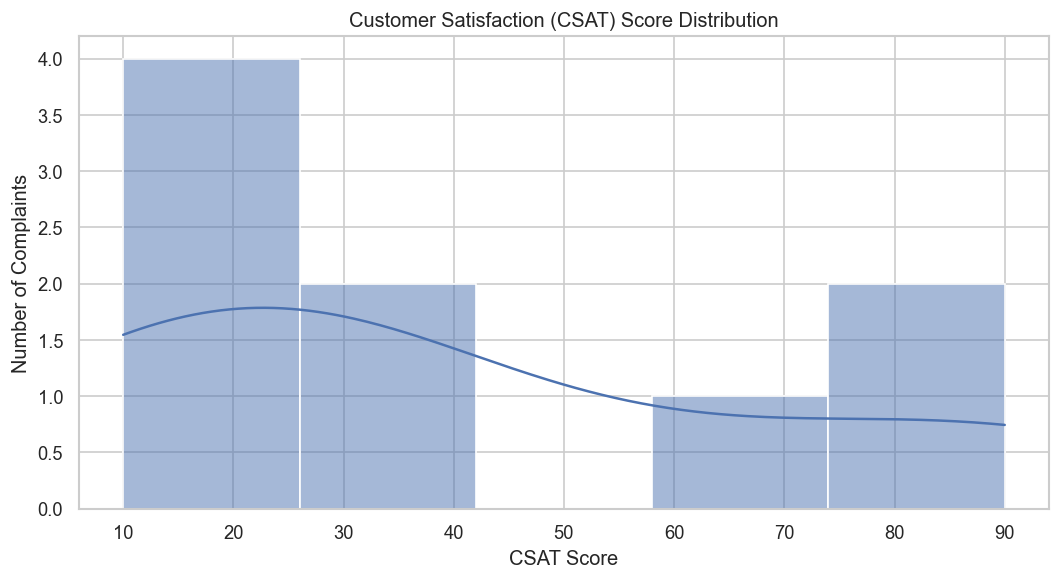

In [253]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_support_clean,
    x="csat_score",
    bins=5,
    kde=True
)

plt.title("Customer Satisfaction (CSAT) Score Distribution")
plt.xlabel("CSAT Score")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.savefig("visualizations/01_csat_distribution.png", dpi=300)
plt.show()

2. Escalation Analysis

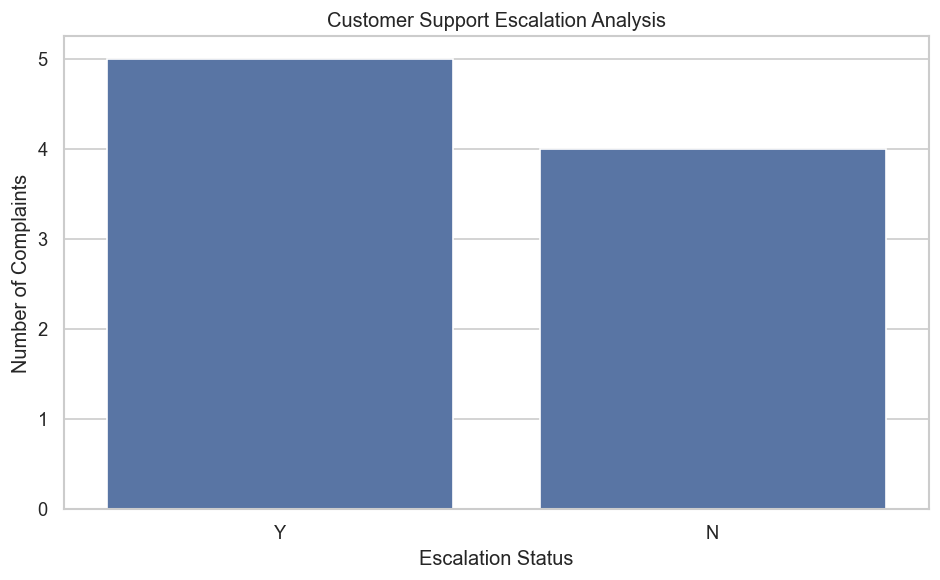

In [254]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_support_clean,
    x="escalations",
    order=df_support_clean["escalations"].value_counts().index
)

plt.title("Customer Support Escalation Analysis")
plt.xlabel("Escalation Status")
plt.ylabel("Number of Complaints")
plt.tight_layout()
plt.savefig("visualizations/02_escalation_analysis.png", dpi=300)
plt.show()

3. Complaint Trend Analysis

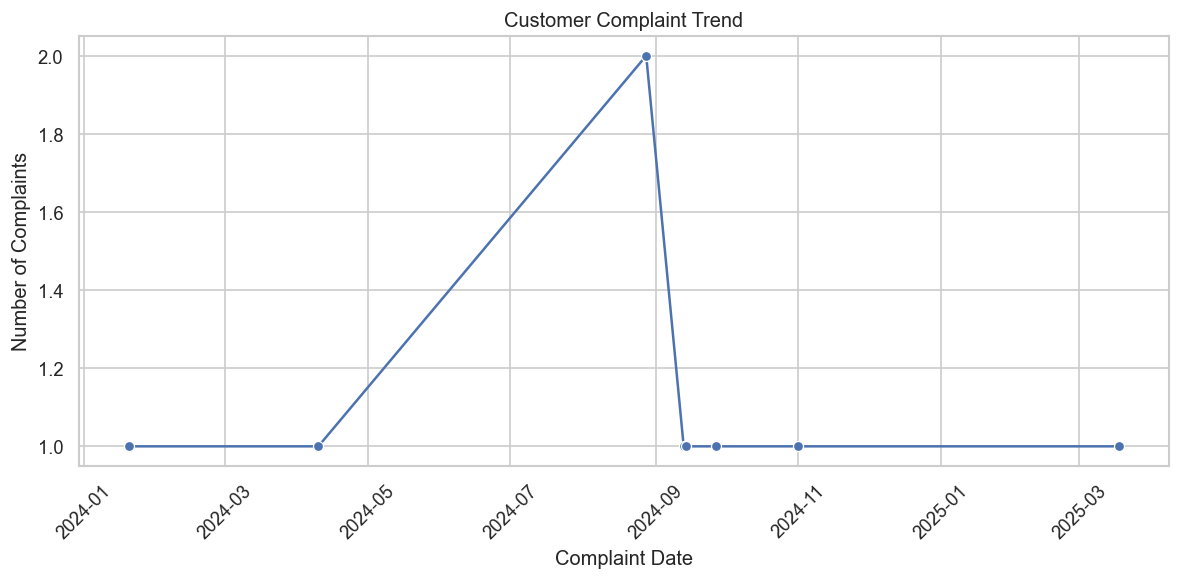

In [255]:
complaint_trend = (
    df_support_clean
    .dropna(subset=["complaint_date"])
    .groupby("complaint_date")
    .size()
    .reset_index(name="complaint_count")
    .sort_values("complaint_date")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=complaint_trend,
    x="complaint_date",
    y="complaint_count",
    marker="o"
)

plt.title("Customer Complaint Trend")
plt.xlabel("Complaint Date")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visualizations/03_complaint_trend.png", dpi=300)
plt.show()

4. Customer-wise Complaint Analysis

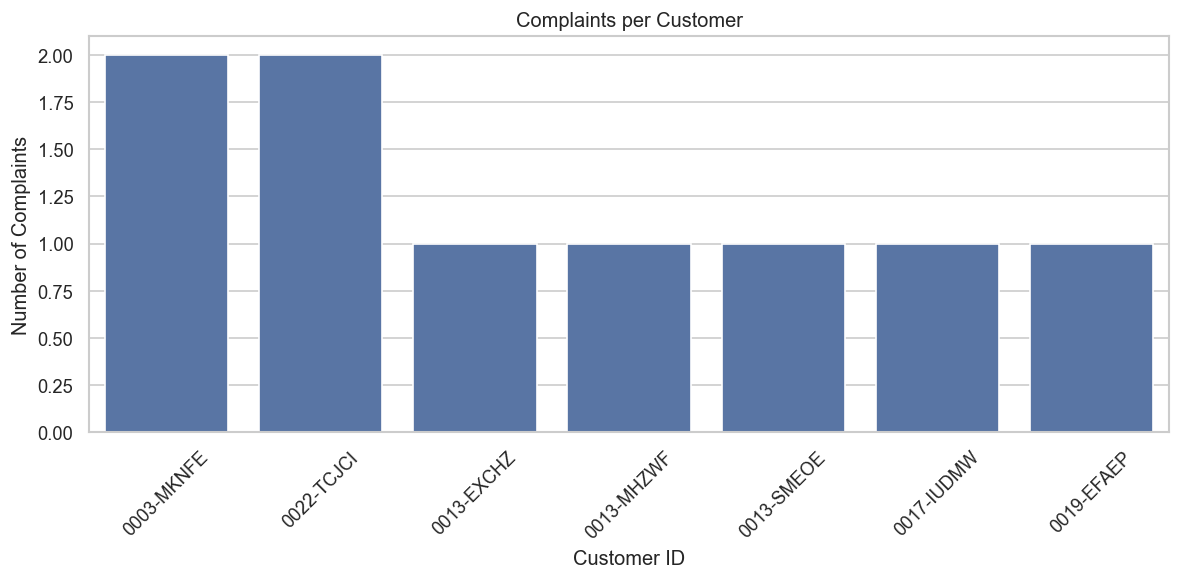

In [256]:
customer_complaints = (
    df_support_clean["customerid"]
    .value_counts()
    .reset_index()
)

customer_complaints.columns = [
    "customerid",
    "complaint_count"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=customer_complaints,
    x="customerid",
    y="complaint_count"
)

plt.title("Complaints per Customer")
plt.xlabel("Customer ID")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visualizations/04_customer_complaints.png", dpi=300)
plt.show()

5. CSAT vs Escalation Analysis

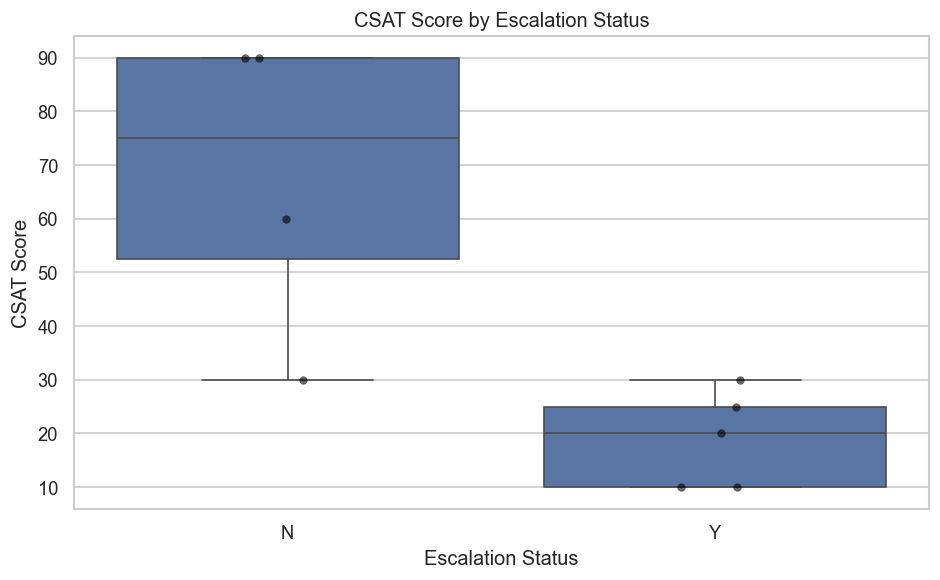

In [257]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_support_clean.dropna(
        subset=["csat_score", "escalations"]
    ),
    x="escalations",
    y="csat_score"
)

sns.stripplot(
    data=df_support_clean.dropna(
        subset=["csat_score", "escalations"]
    ),
    x="escalations",
    y="csat_score",
    color="black",
    alpha=0.6
)

plt.title("CSAT Score by Escalation Status")
plt.xlabel("Escalation Status")
plt.ylabel("CSAT Score")
plt.tight_layout()
plt.savefig("visualizations/05_csat_vs_escalation.png", dpi=300)
plt.show()

6. Customer Feedback Word Analysis

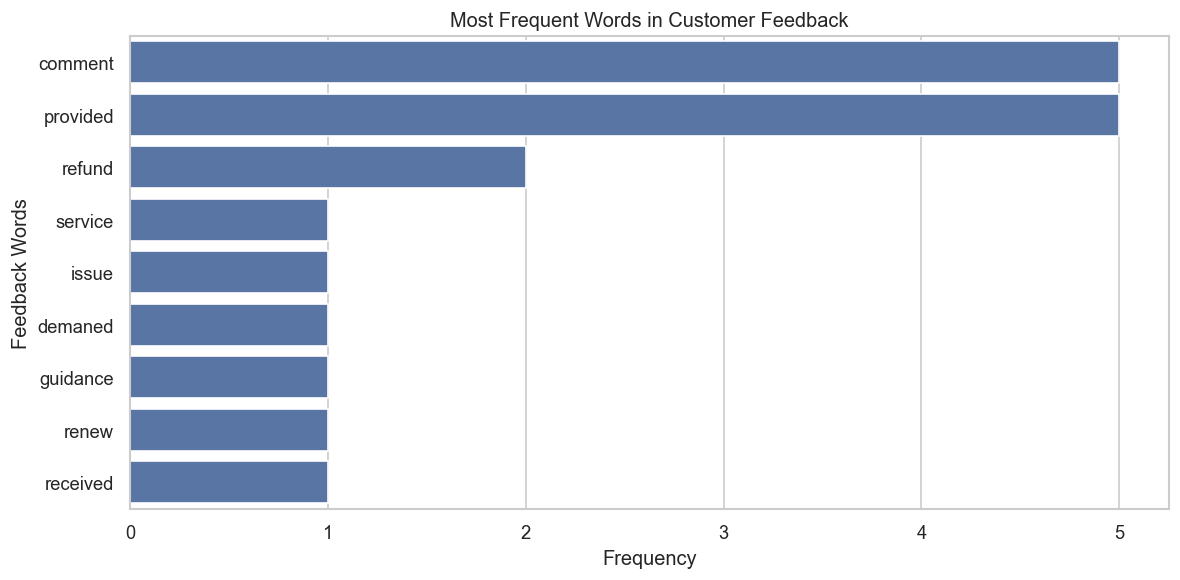

In [258]:
stop_words = {
    "the", "is", "was", "and", "a", "an", "to", "of",
    "for", "in", "on", "it", "this", "that", "with",
    "very", "i", "we", "my", "me", "not", "but"
}

comments = (
    df_support_clean["comment_clean"]
    .dropna()
    .astype(str)
)

words = []

for comment in comments:
    tokens = re.findall(r"[a-zA-Z]+", comment.lower())
    words.extend(
        word for word in tokens
        if word not in stop_words and len(word) > 2
    )

word_counts = Counter(words).most_common(10)

plt.figure(figsize=(10, 5))

if word_counts:
    word_df = pd.DataFrame(
        word_counts,
        columns=["word", "frequency"]
    )

    sns.barplot(
        data=word_df,
        x="frequency",
        y="word"
    )

    plt.title("Most Frequent Words in Customer Feedback")
    plt.xlabel("Frequency")
    plt.ylabel("Feedback Words")
else:
    plt.text(
        0.5, 0.5,
        "Not enough meaningful feedback words",
        ha="center",
        va="center"
    )
    plt.title("Customer Feedback Word Analysis")
    plt.axis("off")

plt.tight_layout()
plt.savefig("visualizations/06_feedback_word_analysis.png", dpi=300)
plt.show()

In [259]:
print("TOTAL COMPLAINTS:",
      len(df_support_clean))

print("\nUNIQUE CUSTOMERS:",
      df_support_clean["customerid"].nunique())

print("\nAVERAGE CSAT SCORE:",
      round(df_support_clean["csat_score"].mean(), 2))

print("\nESCALATED COMPLAINTS:")
print(
    df_support_clean["escalations"]
    .value_counts()
)

print("\nTOP CUSTOMERS BY COMPLAINT COUNT:")
display(customer_complaints.head(10))

print("\nAVERAGE CSAT BY ESCALATION:")
display(
    df_support_clean.groupby("escalations")["csat_score"]
    .mean()
    .round(2)
)

TOTAL COMPLAINTS: 9

UNIQUE CUSTOMERS: 7

AVERAGE CSAT SCORE: 40.56

ESCALATED COMPLAINTS:
escalations
Y    5
N    4
Name: count, dtype: Int64

TOP CUSTOMERS BY COMPLAINT COUNT:


,customerid,complaint_count
0,0003-MKNFE,2
1,0022-TCJCI,2
2,0013-EXCHZ,1
3,0013-MHZWF,1
4,0013-SMEOE,1
5,0017-IUDMW,1
6,0019-EFAEP,1



AVERAGE CSAT BY ESCALATION:


escalations
N    67.5
Y    19.0
Name: csat_score, dtype: float64